In [4]:
import numpy as np
import pandas as pd
from plot_lib.plotylk import plot_lightnings, plot_lines, plot_nodes

def compute_voltage_bins(df,
                         vmin=50,
                         vmax=300,
                         bin_size=25,
                         exceed_value=None):

    # Remove first column if it's the stroke label
    df_numeric = df.drop(columns=["Column1"], errors="ignore")

    bins = np.arange(vmin, vmax + bin_size, bin_size)

    results = {}

    for node in df_numeric.columns:

        values = df_numeric[node]

        # Histogram counts
        counts, edges = np.histogram(values, bins=bins)

        table = pd.DataFrame({
            "bin_min": edges[:-1],
            "bin_max": edges[1:],
            "count": counts
        })

        # Exceedance count
        if exceed_value is not None:
            table["exceed_count"] = [
                (values >= edge).sum() for edge in edges[:-1]
            ]

        results[node] = table

    return results

In [5]:
import seaborn as sns
import matplotlib.pyplot as plt

def plot_node_bins(bin_table, node_name):

    sns.set_theme(style="whitegrid", context="talk")

    bin_table["bin_label"] = (
        bin_table["bin_min"].astype(str)
        + "-"
        + bin_table["bin_max"].astype(str)
    )

    plt.figure(figsize=(10,6))
    sns.barplot(
        x="bin_label",
        y="count",
        data=bin_table,
        color="steelblue"
    )

    plt.xticks(rotation=45)
    plt.title(f"Voltage Distribution - {node_name}")
    plt.xlabel("Voltage Bin")
    plt.ylabel("Number of Events")
    plt.tight_layout()
    plt.show()


In [6]:
def plot_exceedance_across_nodes(df, threshold):

    df_numeric = df.drop(columns=["Column1"], errors="ignore")

    exceed_counts = (df_numeric >= threshold).sum()

    result_df = exceed_counts.reset_index()
    result_df.columns = ["Node", "Event_Count"]

    sns.set_theme(style="whitegrid", context="talk")

    plt.figure(figsize=(10,6))
    sns.lineplot(data=result_df,
                x="Node",
                y="Event_Count",
                palette="viridis")

    plt.title(f"Events Exceeding {threshold} kV")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

    return result_df

In [7]:
from matplotlib.colors import LinearSegmentedColormap

def gray_to_red_cmap():
    return LinearSegmentedColormap.from_list(
        "gray_red",
        ["lightgray", "red"]
    )
def plot_network_heatmap(df_nodes,
                         df_lines,
                         df_voltage,
                         threshold,
                         coord_type="cartesian",
                         cmap="Reds",
                         ax=None):

    import seaborn as sns
    sns.set_theme(style="white", context="talk")

    if ax is None:
        fig, ax = plt.subplots(figsize=(10,8))
    else:
        fig = ax.figure

    # ---- Compute exceedance ----
    df_numeric = df_voltage #.drop(columns=["Column1"], errors="ignore")
    exceed_counts = (df_numeric >= threshold).sum()

    df_plot = df_nodes.copy()
    df_plot["Event_Count"] = df_plot["Name"].map(exceed_counts)
    if cmap == "gray_red":
        cmap = LinearSegmentedColormap.from_list(
            "gray_red", ["lightgray", "red"]
        )
    elif cmap == "green_red":
        cmap = LinearSegmentedColormap.from_list(
            "green_red", ["#50a75e", "#800000"]
        )
    elif cmap == "gray_darkred":
        cmap = LinearSegmentedColormap.from_list(
            "gray_darkred", ["#d3d3d3", "#800000"]
        )
    else:
        cmap="reds"
    # ---- Call base plotting functions ----
    plot_lines(df_lines,
               coord_type=coord_type,
               ax=ax)

    plot_nodes(df_plot,
               value_col="Event_Count",
               coord_type=coord_type,
               cmap="Reds",
               node_size=120,
               ax=ax)

    ax.set_title(f"Network Heatmap - Events ≥ {threshold} kV")

    return fig, ax

In [20]:
import Network_lib as nl
import pandas as pd
import Lightning_lib as ls

from Network_lib.Node import PhaseName

In [21]:
class Trf_parameters():
        def __init__(self,A,B,C,D):
            self.CapHV=A
            self.CapHL=B
            self.CapLV=C
            self.Ground=D
def data_setting():
    #Definition Nodes
    #id of the node must be integer or string of maximum 4 characters, preferably integer, label is the name of the node, x and y are the coordinates in meters from the initial location defined in the network_setting function, if ctype is "rel" the coordinates are relative to the initial location, if ctype is "abs" the coordinates are absolute from the initial location
    Nodes = pd.DataFrame(columns=['id', 'label','y','x'])
    Nodes.loc[0] = [1, 'N1', 125300, 103000]
    Nodes.loc[1] = [2, 'N2', 125450, 103050]
    Nodes.loc[2] = [3, 'N3', 125500, 103100]
    Nodes.loc[3] = [4, 'N4', 125650, 103150]
    Nodes.loc[4] = [5, 'N5', 125700, 103200]
    Nodes.loc[5] = [6, 'N6', 125750, 103250]
    Nodes.loc[6] = [7, 'N7', 125700, 103400]
    Nodes.loc[7] = [8, 'N8', 125450, 103150]
    Nodes.loc[8] = [9, 'N9', 125900, 103400]
    Nodes.loc[9] = [10, 'N10', 125950, 103450]

    #Definition Lines
    "from_node to to_node must be the id of the nodes defined in the Nodes dataframe, configuration_type must be one of the configurations defined in the network_setting function"
    Lines=pd.DataFrame(columns=['id', 'label', 'from_node', 'to_node','configuration_type'])
    Lines.loc[0] = [1, 'L1', 'N1', 'N2','Config_A']
    Lines.loc[1] = [2, 'L2', 'N2', 'N3','Config_A']
    Lines.loc[2] = [3, 'L3', 'N3', 'N4','Config_B']
    Lines.loc[3] = [4, 'L4', 'N4', 'N5','Config_B']
    Lines.loc[4] = [5, 'L5', 'N5', 'N6','Config_B']
    Lines.loc[5] = [6, 'L6', 'N6', 'N7','Config_B']
    Lines.loc[6] = [7, 'L7', 'N4', 'N8','Config_B']
    Lines.loc[7] = [8, 'L8', 'N5', 'N9','Config_B']
    Lines.loc[8] = [9, 'L9', 'N6', 'N10','Config_B']




    #Definition high frequency transformer types
    
    Tr1= Trf_parameters(340e-12, 744e-12, 215e-12, 10)
    Tr2= Trf_parameters(440e-12, 644e-12, 115e-12, 20)

    #Transformers connections
    Transformers=pd.DataFrame(columns=['id', 'label', 'from_node', 'phases','trf_type'])
    Transformers.loc[0] = [1, 'T1', 'N2', 111,'Tr1']
    Transformers.loc[1] = [2, 'T2', 'N1', 11,'Tr2']
    Transformers.loc[2] = [3, 'T3', 'N3', 101,'Tr1']
    #Transformers Types

    Trftype=pd.DataFrame(columns=['id', 'CHV', 'CLV', 'CHL', 'ground'])
    Trftype.loc[0] = ['Tr1', 340e-12, 215e-12, 744e-12,10.0]
    Trftype.loc[1] = ['Tr2', 440e-12, 115e-12, 644e-12,20.0]


    #surge arresters
    Surge_Arresters=pd.DataFrame(columns=['id', 'label', 'node', 'phases','file'])
    Surge_Arresters.loc[0] = [1, 'SA1', 'N2',111,'SAIEEE_3ph.pch']
    Surge_Arresters.loc[1] = [2, 'SA2', 'N3',1,'saieee_15kV_1ph.pch']
    return Nodes, Lines, Transformers, Surge_Arresters, Trftype
def network_setting(Nodes: pd.DataFrame, Lines:pd.DataFrame, Transformers:pd.DataFrame, Surge_Arresters:pd.DataFrame,Trftype:pd.DataFrame):
    # Create a new network
    len_nodes= len(Nodes)
    len_lines= len(Lines)
    len_transformers= len(Transformers)
    len_surge_arresters= len(Surge_Arresters)
    if len_nodes==0:
        raise ValueError("No nodes defined in the network.")
    elif len_lines==0:
        raise ValueError("No lines defined in the network.")
    print(f"Creating network with {len_nodes} nodes, {len_lines} lines, {len_transformers} transformers, and {len_surge_arresters} surge arresters.")
    # Initial location for coordinate conversion
    #Init_lat_lon= nl.PointLatLng(Nodes.loc[0,'x'], Nodes.loc[0,'y'])
    initxy=nl.PointXY(Nodes.loc[1,'x'], Nodes.loc[1,'y'])

    net = nl.Network('uid_01','Example_Network2')
    net.InitXY=initxy
    
    Conductor_1 = nl.Conductor()
    Conductor_1.Radio = .005
    Conductor_1.Resistance = 1
    Conductor_1.Name = "Conductor ACSR"
    Conductor_1.Description = "Conductor Calibre 2/0 - catálogo CENTELSA"

    # Dfining Configurations, it culd be severalconfigurations with different number of conductors and geometries, each line must be assigned to one of the configurations
    Config1 = nl.Configuration_Type()
    Config1.id = "LAR1"
    Config1.Name = "Mono LAR1"
    Config1.Description = "Linea un solo conductor"
    Config1.Add_conductor(Conductor_1, 10, 0)
    Config1.Add_conductor(Conductor_1, 10, 2)
    Config1.gen_parameters()

    nl.Transformer
    
    for n in Nodes.itertuples():
       net.AddNode(n.x, n.y,Nodeidx=n.id,ctype="abs", label=n.label)  #You can use also ctype="rel" if you want to add nodes using coordinates relative to the initial location
    # Add lines
    for l in Lines.itertuples():
        from_node = net.Nodes.GetByName(l.from_node)
        to_node = net.Nodes.GetByName(l.to_node)
        net.AddLine(from_node, to_node, Config1)
    for li in net.Lines:
        li.isFDTD=True
    net.MakeLccFile()
    # Add transformers

    for t in Transformers.itertuples():
        node_trf=t.from_node
        trf_types = Trftype.loc[Trftype['id'] == t.trf_type]
        trf_type = trf_types.iloc[0] if not trf_types.empty else None
        net.AddTransf(label=t.label,CHV=float(trf_type.CHV), CLV=float(trf_type.CLV), CHL=float(trf_type.CHL), ground=float(trf_type.ground), NHV=node_trf,  phases=t.phases)
    
    from pathlib import Path
    from Network_lib.utils import get_short_path
    
    ruta = Path('surges')
    for sa in Surge_Arresters.itertuples():
        node_sa=net.Nodes.GetByName(sa.node)
        filename_short=str(ruta / sa.file)
        #filename_short=get_short_path(filename_short)
        net.AddSurgeArrester(ni=node_sa,pch_file=filename_short, Phase_connect=sa.phases)
    return net

In [22]:
print("Starting network creation...")
Nodes,Lines,Transformers,Surge_Arresters,Trftype = data_setting()
print("Data setting completed.")
print("Creating network...")
#net = nl.Network('c','a')
net=network_setting(Nodes,Lines,Transformers,Surge_Arresters,Trftype)
net.MakeAtpFile()

Starting network creation...
Data setting completed.
Creating network...
Creating network with 10 nodes, 9 lines, 3 transformers, and 2 surge arresters.
Initializing network...
Short path: lcc\lcc_001.lib
Running on Windows
Short path: lcc\lcc_002.lib
Running on Windows
Short path: lcc\lcc_003.lib
Running on Windows
Short path: lcc\lcc_004.lib
Running on Windows
Short path: lcc\lcc_005.lib
Running on Windows
Short path: lcc\lcc_006.lib
Running on Windows
Short path: lcc\lcc_007.lib
Running on Windows
Short path: lcc\lcc_008.lib
Running on Windows
Short path: lcc\lcc_009.lib
Running on Windows


In [54]:
import pandas as pd

df_voltage = pd.read_csv("resultados2.csv")
#print(df_voltage.head())

voltage_cols = df_voltage.columns
df_voltage[voltage_cols] = df_voltage[voltage_cols]/1000. 
#df_voltage.drop(columns=["Case"], inplace=True)
df_max = df_voltage[voltage_cols[-1]].copy()
df_voltage.drop(columns=[voltage_cols[-1]], inplace=True, errors="ignore")

print(df_max.head())

0    127.112970
1    152.206890
2     91.615414
3    252.115380
4    148.901230
Name: MAX, dtype: float64


In [43]:
bins_dict = compute_voltage_bins(
    df_voltage,
    vmin=20,
    vmax=300,
    bin_size=5,
    exceed_value=200
)


In [46]:
node_table = bins_dict["v:N0006A:      "]

print(node_table)

    bin_min  bin_max  count  exceed_count
0        20       25      0          1605
1        25       30      5          1605
2        30       35      7          1600
3        35       40     35          1593
4        40       45     45          1558
5        45       50     51          1513
6        50       55     49          1462
7        55       60     43          1413
8        60       65     55          1370
9        65       70     77          1315
10       70       75    131          1238
11       75       80    137          1107
12       80       85    112           970
13       85       90    125           858
14       90       95    101           733
15       95      100     86           632
16      100      105     79           546
17      105      110     68           467
18      110      115     67           399
19      115      120     40           332
20      120      125     41           292
21      125      130     38           251
22      130      135     22       

C:\Users\Ernesto Pérez\AppData\Local\Temp\ipykernel_2204\1876853847.py:13: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.lineplot(data=result_df,


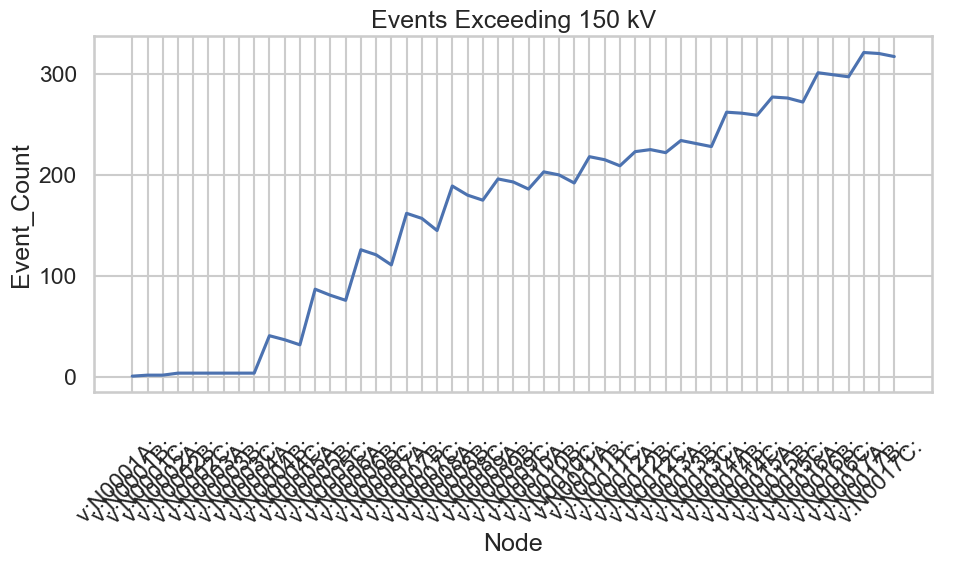

In [45]:
result_df = plot_exceedance_across_nodes(
    df_voltage,
    threshold=150
)

C:\Users\Ernesto Pérez\AppData\Local\Temp\ipykernel_2204\1876853847.py:13: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.lineplot(data=result_df,


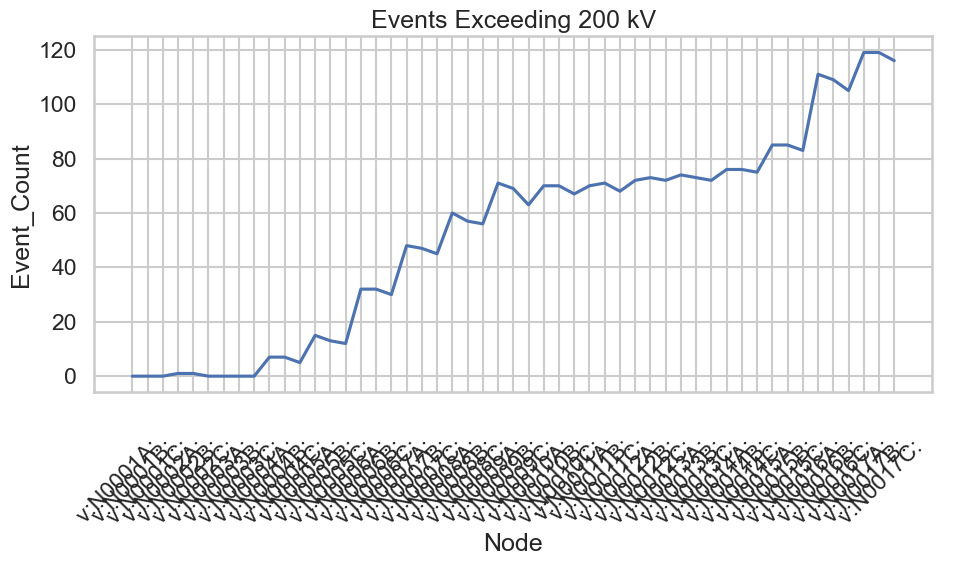

In [53]:
result_df = plot_exceedance_across_nodes(
    df_voltage,
    threshold=200
)

(<Figure size 1000x800 with 2 Axes>,
 <Axes: title={'center': 'Network Heatmap - Events ≥ 100 kV'}, xlabel='X', ylabel='Y'>)

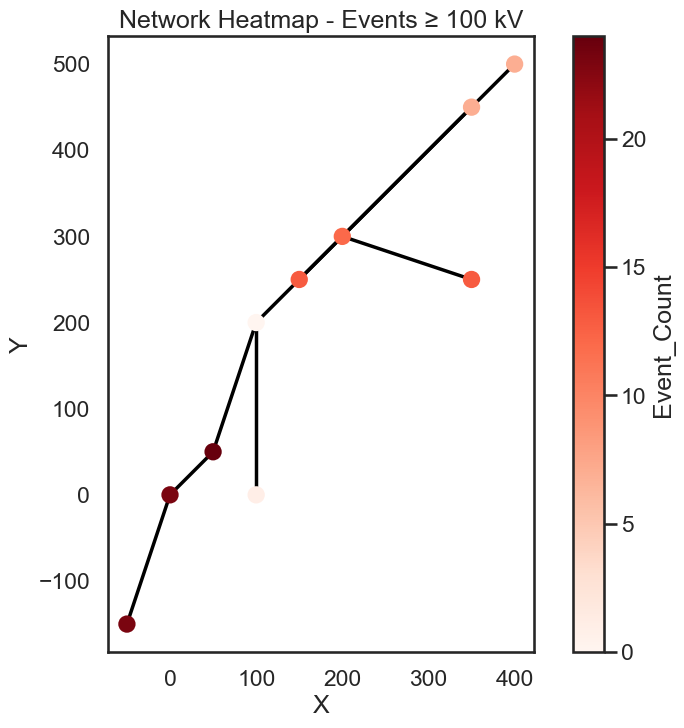

In [28]:
net.create_dataframes()
plot_network_heatmap(
    net.df_nodes,
    net.df_lines,
    df_voltage,
    threshold=100,
    cmap="green_red"
)